# 4. A KDE detector for MetroPT

Notebook 1 showed that three of the four reported failures are visible by eye as a
jump in `DV_pressure`. Here we build something that finds them without being told
what to look for.

The idea is the one from lecture block 1: fit a density model to a stretch of normal
operation, then score every later point by how unlikely it is under that model.
Unlikely means anomalous.

The output of this notebook is a single score series saved to `results/`, which
notebook 6 turns into alarms and a cost.

In [1]:
import zipfile

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KernelDensity

SENSORS = ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs',
           'Oil_temperature', 'Motor_current']

FAILURES = [
    ('F1', '2020-04-18', '2020-04-18'),
    ('F2', '2020-05-29', '2020-05-30'),
    ('F3', '2020-06-05', '2020-06-07'),
    ('F4', '2020-07-15', '2020-07-15'),
]

## The data

Same loading and aggregation as notebook 1: 10-minute means of the seven analogue
sensors.

In [2]:
with zipfile.ZipFile('../data/metropt3.zip') as z:
    name = [n for n in z.namelist() if n.endswith('.csv')][0]
    with z.open(name) as f:
        raw = pd.read_csv(f)

raw['timestamp'] = pd.to_datetime(raw['timestamp'])
data = raw.sort_values('timestamp').set_index('timestamp')[SENSORS]
data = data.resample('10min').mean().dropna()

print(f'{len(data):,} ten-minute rows from {data.index.min()} to {data.index.max()}')

25,521 ten-minute rows from 2020-02-01 00:00:00 to 2020-09-01 03:50:00


## Which period counts as normal?

The model only ever sees this stretch, so the choice matters more than anything else
in the notebook.

The first reported failure is on 18 April, so anything before that is a candidate.
Notebook 1 also found that February looks different from March onwards, which gives
us two options to compare.

In [3]:
candidates = {
    'February only':    data.loc[:'2020-02-29'],
    'February + March': data.loc[:'2020-03-31'],
}

print('standard deviation of each sensor within the candidate periods\n')
print(pd.DataFrame({name: part.std() for name, part in candidates.items()}).round(4))

standard deviation of each sensor within the candidate periods

                 February only  February + March
TP2                     0.7642            1.7755
TP3                     0.3935            0.4734
H1                      0.8182            1.8625
DV_pressure             0.0136            0.1271
Reservoirs              0.3933            0.4732
Oil_temperature         3.2780            5.9794
Motor_current           1.3158            1.5912


`DV_pressure` barely moves in February: its standard deviation is a thousandth of
what it is once March is included. That is the same thing notebook 1 ran into, and it
matters here because `StandardScaler` divides by it. Train on February alone and
every later `DV_pressure` reading becomes an enormous number, which would swamp the
other six sensors and effectively turn our seven-sensor model into a one-sensor
model.

So we train on **February and March**. It is still entirely before the first reported
failure, and it contains enough variation for the scaling to behave.

That choice is worth remembering: it means we are *not* treating the early spikes in
March as anomalies. We are telling the model they are normal. Whether that is right
is an open question in `DECISIONS.md`.

In [4]:
train = data.loc[:'2020-03-31']

scaler = StandardScaler().fit(train)
X_train = scaler.transform(train)
X_all = scaler.transform(data)

print(f'training on {len(train):,} rows, scoring all {len(data):,}')

training on 7,422 rows, scoring all 25,521


## Fitting the density

`KernelDensity` places a small Gaussian bump on every training point and adds them
up. Where training points were dense the total is high, and a new point landing there
looks normal. Where there were none it is near zero, and a point landing there looks
strange.

We score with the **negative** log density, so that a high score means unusual. That
is the only transformation applied: no smoothing, no thresholding yet.

We fit on 5000 randomly chosen training rows rather than all 8640. The normal region
is one blob and 5000 points describe it perfectly well, while scoring runs several
times faster.

In [5]:
rng = np.random.default_rng(0)
sample = rng.choice(len(X_train), size=5000, replace=False)


def kde_scores(bandwidth):
    '''Fit a KDE on the training sample and score every row. High = unusual.'''
    kde = KernelDensity(bandwidth=bandwidth).fit(X_train[sample])
    return pd.Series(-kde.score_samples(X_all), index=data.index)

## Choosing the bandwidth

The bandwidth is how wide each bump is, and it is the one parameter we have to set.
Too narrow and the model memorises the training points, so ordinary variation looks
anomalous. Too wide and everything blurs together and nothing looks anomalous.

Rather than argue about it, we try three values an order of magnitude apart and look
at what each does to the failures.

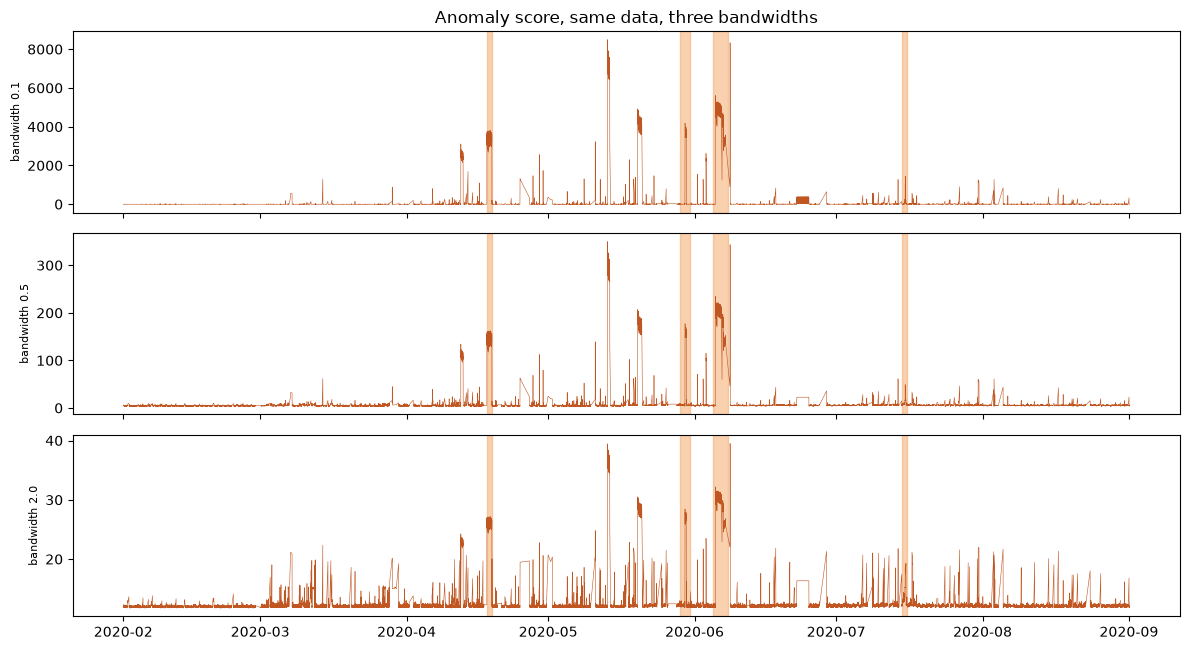

In [6]:
bandwidths = [0.1, 0.5, 2.0]
tried = {b: kde_scores(b) for b in bandwidths}

fig, axes = plt.subplots(len(bandwidths), 1, figsize=(12, 2.2 * len(bandwidths)),
                         sharex=True)

for ax, b in zip(axes, bandwidths):
    ax.plot(tried[b].index, tried[b], lw=0.4, color='#c05621')
    ax.set_ylabel(f'bandwidth {b}', fontsize=8)
    for _, start, end in FAILURES:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end) + pd.Timedelta(days=1),
                   color='sandybrown', alpha=0.5)

axes[0].set_title('Anomaly score, same data, three bandwidths')
plt.tight_layout()

To compare them with a number rather than by eye, we ask how far the failure periods
stand above everything else. A gap of 1 would mean the failures are indistinguishable
from ordinary variation.

In [7]:
in_failure = pd.Series(False, index=data.index)
for _, start, end in FAILURES:
    in_failure.loc[start:pd.Timestamp(end) + pd.Timedelta(days=1)] = True

summary = pd.DataFrame({
    'median normal': {b: s[~in_failure].median() for b, s in tried.items()},
    '99th pct normal': {b: s[~in_failure].quantile(0.99) for b, s in tried.items()},
    'median in failure': {b: s[in_failure].median() for b, s in tried.items()},
})
summary['separation'] = summary['median in failure'] / summary['99th pct normal']
summary.round(2)

,median normal,99th pct normal,median in failure,separation
0.1,-1.37,2548.64,3012.15,1.18
0.5,5.19,112.09,130.15,1.16
2.0,12.03,22.98,25.17,1.09


## Choosing one

The three bandwidths rank the failures almost identically. The separation column
barely moves, and F1 and F3 stand out under all three while F4 stands out under none.
This parameter is not where the decision lies.

We take 0.5. At 0.1 the scores run into the thousands and swing on a handful of
training points; at 2.0 everything is squeezed into a narrow range. The middle value
keeps the numbers readable without changing any conclusion.

The table shows something more important than the bandwidth, though. At 0.5 the
median normal score is 5, but the 99th percentile of normal is 112, against a median
of 130 inside the failures. **Ordinary operation regularly scores as high as a leak.**
A threshold that catches the failures will fire at other times too. That is not a
flaw to tune away; it is the thing notebook 6 has to put a price on.

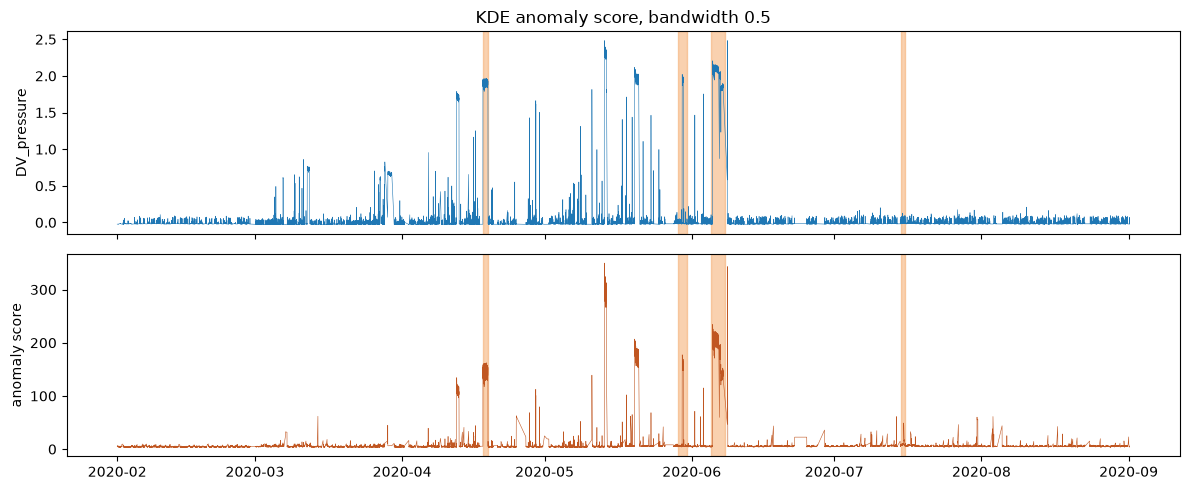

In [8]:
BANDWIDTH = 0.5
scores = tried[BANDWIDTH]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True)

ax1.plot(data.index, data['DV_pressure'], lw=0.4)
ax1.set_ylabel('DV_pressure')

ax2.plot(scores.index, scores, lw=0.4, color='#c05621')
ax2.set_ylabel('anomaly score')

for ax in (ax1, ax2):
    for _, start, end in FAILURES:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end) + pd.Timedelta(days=1),
                   color='sandybrown', alpha=0.5)

ax1.set_title(f'KDE anomaly score, bandwidth {BANDWIDTH}')
plt.tight_layout()

## How high does the score go during each failure?

Not a verdict, just a look before notebook 6 turns these into alarms and costs.

In [9]:
rows = []
for label, start, end in FAILURES:
    window = scores.loc[start:pd.Timestamp(end) + pd.Timedelta(days=1)]
    rows.append({
        'failure': label,
        'peak score': window.max(),
        'above 99th pct of normal': f'{(window > summary.loc[BANDWIDTH, "99th pct normal"]).mean():.0%}',
    })

pd.DataFrame(rows).set_index('failure').round(1)

,peak score,above 99th pct of normal
failure,,
F1,162.5,99%
F2,177.4,14%
F3,234.7,83%
F4,49.2,0%


## Saving

One column, indexed by timestamp. Notebook 6 reads this.

In [10]:
import os

os.makedirs('../results', exist_ok=True)
scores.rename('score').to_csv('../results/metropt_scores.csv')

print(f'saved {len(scores):,} scores to ../results/metropt_scores.csv')

saved 25,521 scores to ../results/metropt_scores.csv


## What this notebook settles, and what it does not

**Settled.** A seven-sensor KDE fitted on February and March ranks two of the four
reported failures clearly above normal operation, without being told anything about
what a leak looks like: 99 % of F1 and 83 % of F3 sit above the 99th percentile of
normal. F2 reaches it for 14 % of its window, which matches notebook 1, where the
plateau covered only part of the two-day label. F4 never reaches it, which also
matches notebook 1.

**Not settled, and this is the real finding.** The gap is narrow. The 99th percentile
of ordinary operation scores 112; the median inside a failure is 130. So the question
is not whether we can see the failures, but how many false alarms we are willing to
pay for seeing them. That is notebook 6.

**Known weaknesses**, all recorded in `DECISIONS.md`:

- Training on March means the early `DV_pressure` spikes are treated as normal. If
  those spikes are early signs of the April leak, we have taught the model to ignore
  exactly what we want it to catch.
- Each row is scored on its own. A single odd reading scores the same as an hour of
  them, although only the second is worth sending anyone out for. A sliding window
  would fix this and is the obvious next improvement.
- Dropping rows with gaps leaves 25,521 of the 30,696 ten-minute slots, so the series
  is not evenly spaced. Notebook 6 should not assume it is.